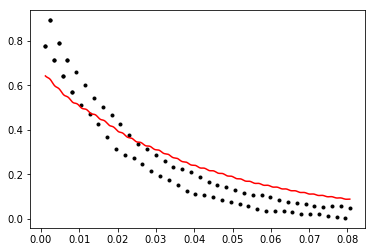

[  4.70000000e-03   3.90000000e-03   6.00000000e-04   1.20000000e-02
   7.00000000e-02   8.80000000e-03   9.00000000e-01] [  2.72223979e-17   6.56810357e-01   4.41795071e-20   2.02955000e-23
   6.54204262e-27   3.73460839e-03   9.49681929e-03]


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.optimize import least_squares

#define fat-water interaction equation
def fat_water(TE, a, b, c, d, e, f, g): #T2star, Fppmn, magField and HydroGyro constants must be loaded beforehand!
    return np.absolute(a*np.exp(-TE/T2star[0])*np.exp((2.*np.pi*1j*Fppmn[0]*magField*hydroGyro/1e6)*TE) + 
                       b*np.exp(-TE/T2star[1])*np.exp((2.*np.pi*1j*Fppmn[1]*magField*hydroGyro/1e6)*TE) + 
                       c*np.exp(-TE/T2star[2])*np.exp((2.*np.pi*1j*Fppmn[2]*magField*hydroGyro/1e6)*TE) + 
                       d*np.exp(-TE/T2star[3])*np.exp((2.*np.pi*1j*Fppmn[3]*magField*hydroGyro/1e6)*TE) + 
                       e*np.exp(-TE/T2star[4])*np.exp((2.*np.pi*1j*Fppmn[4]*magField*hydroGyro/1e6)*TE) +
                       f*np.exp(-TE/T2star[5])*np.exp((2.*np.pi*1j*Fppmn[5]*magField*hydroGyro/1e6)*TE) +
                       g*np.exp(-TE/T2star[6])*np.exp((2.*np.pi*1j*Fppmn[6]*magField*hydroGyro/1e6)*TE))

#initialize constants
fatPercent = 0.1

magField = 3.0 #tesla

hydroGyro = 42.57e6 #Hz/T

T2star = np.array([0.030,\
                   0.040,\
                   0.051,\
                   0.052,\
                   0.062,\
                   0.083,\
                   0.023])#seconds

Fppmn = np.array([5.3,\
                  4.2,\
                  2.75,\
                  2.1,\
                  1.3,\
                  0.9,\
                  4.7])#ppm

rho = np.array([fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent]) #dimensionless #last is water

#define echo times
n_echoes = 7
xdata = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True) #TE acquisition times for n echoes

#call fat-water function to get original values
ydata = fat_water(xdata, *rho)

#plot
plt.plot(xdata,ydata, '.k')

#fitting - aparentemente só funciona para initial guess = rho ou com pequeno desvio!
bd = (0, [1., 1., 1., 1., 1., 1., 1.]) # Bounds
#init_guess = rho
init_guess = rho+np.random.rand()*0.2
#init_guess = [0.5,0.5,0.5,0.5,0.5,0.5,0.5]

    #get optimal parameters
fitted_param, pcov = curve_fit(fat_water, xdata, ydata, bounds=bd, p0=init_guess)

    #generate time series
x_continuous = np.linspace(xdata.min(), xdata.max(), 1000)    
    #generate curve
y_fitted = fat_water(x_continuous, *fitted_param)

#plot
plt.plot(x_continuous, y_fitted, '-r')
plt.show()

print rho, fitted_param